In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/cdr0101/netflix-dataset/netflix_titles.csv



CINESCOPE - NETFLIX CONTENT EXPLORER
Dataset: /kaggle/input/datasets/cdr0101/netflix-dataset/netflix_titles.csv
Total titles: 8807
Movies: 6131
TV Shows: 2676
Countries: 122
Genres: 42
Release years: 1925 - 2021

FIRST 10 TITLES
show_id                            title    type  release_year rating
     s1             Dick Johnson Is Dead   Movie          2020  PG-13
     s2                    Blood & Water TV Show          2021  TV-MA
     s3                        Ganglands TV Show          2021  TV-MA
     s4            Jailbirds New Orleans TV Show          2021  TV-MA
     s5                     Kota Factory TV Show          2021  TV-MA
     s6                    Midnight Mass TV Show          2021  TV-MA
     s7 My Little Pony: A New Generation   Movie          2021     PG
     s8                          Sankofa   Movie          1993  TV-MA
     s9    The Great British Baking Show TV Show          2021  TV-14
    s10                     The Starling   Movie          2021  PG-13


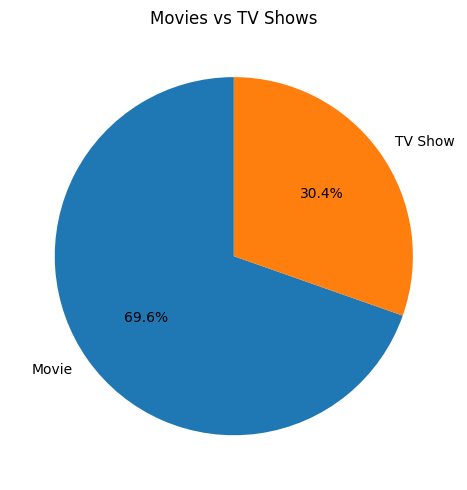

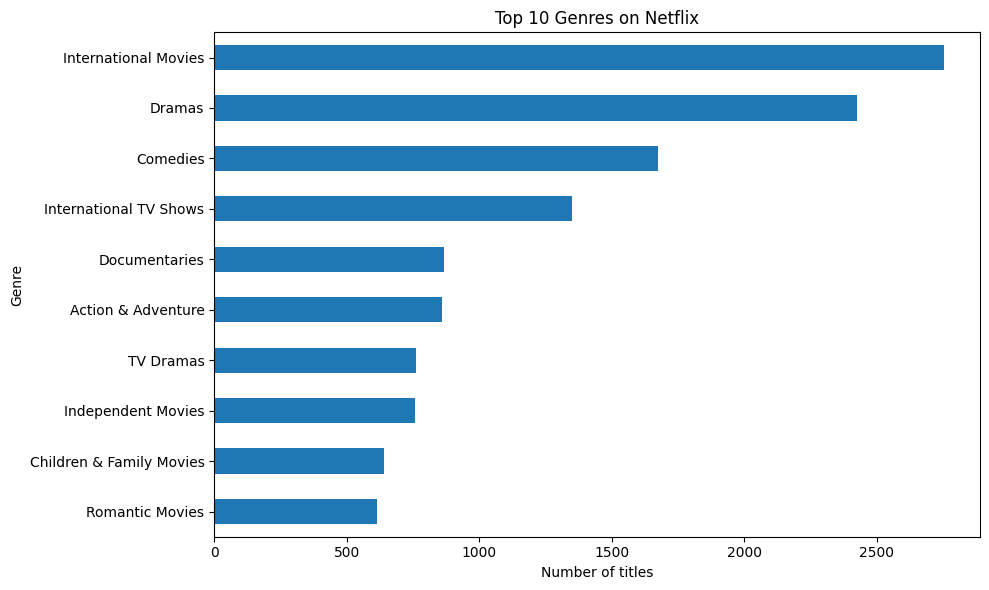

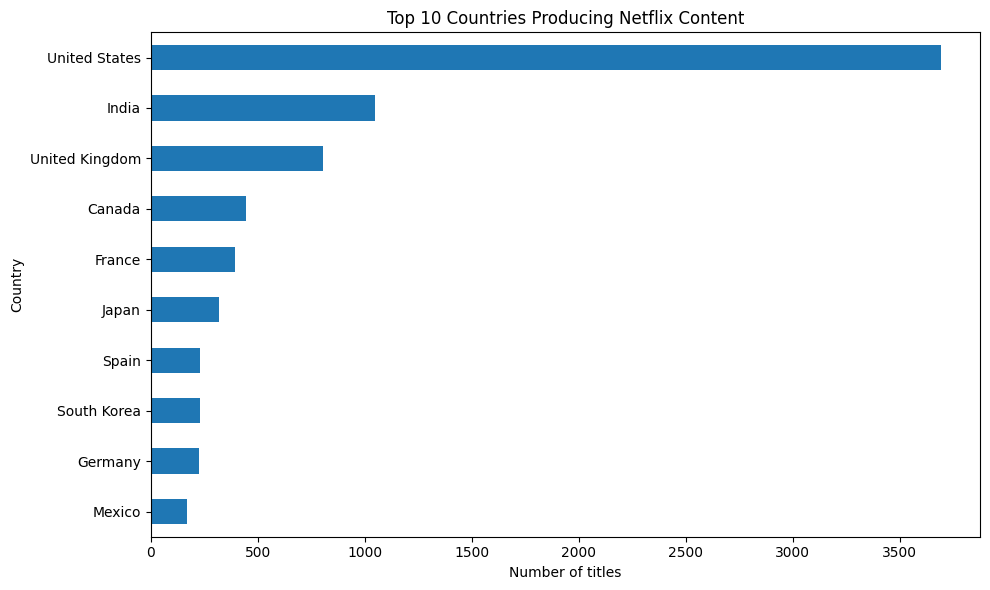

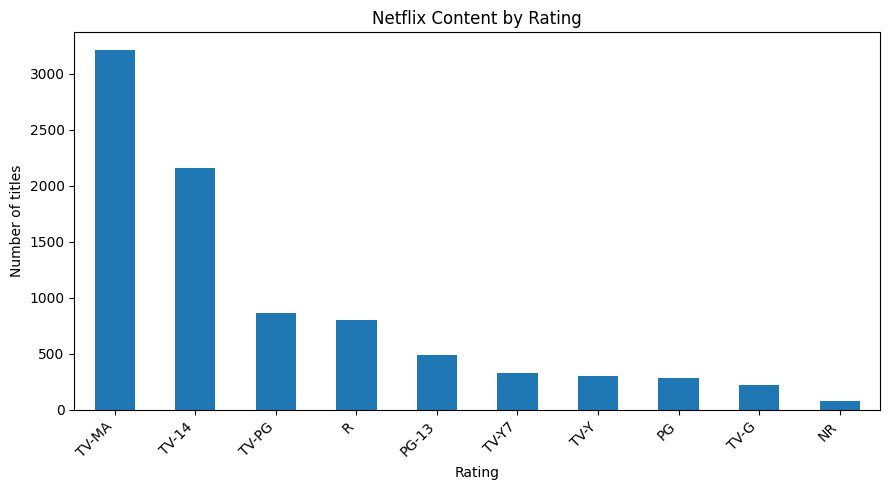

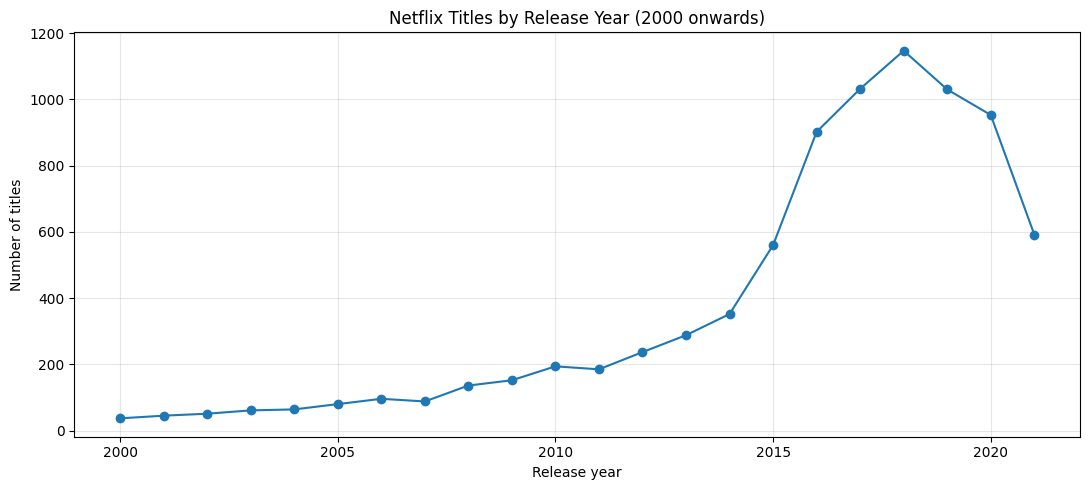


SAMPLE RECOMMENDATIONS
Selected title: Dick Johnson Is Dead
show_id                                   title  type  release_year                             listed_in  similarity_score
  s2351                               Woodshock Movie          2017 Dramas, Independent Movies, Thrillers             0.238
  s7016                      How to Be a Player Movie          1997                              Comedies             0.216
  s5234 The Death and Life of Marsha P. Johnson Movie          2017           Documentaries, LGBTQ Movies             0.178
  s7455                        Midnight Special Movie          2016  Action & Adventure, Sci-Fi & Fantasy             0.178
  s6554                                Daffedar Movie          2017          Dramas, International Movies             0.174

SAMPLE SEARCH: 'love'
show_id                  title    type  release_year rating
    s25                  Jeans   Movie          1998  TV-14
    s26   Love on the Spectrum TV Show          2021

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

# Find the project folder safely (works in a .py file and in a notebook)
try:
    BASE_DIR = os.path.dirname(os.path.abspath(__file__))
except NameError:
    BASE_DIR = os.getcwd()


def find_dataset():
    """Find netflix_titles.csv in common local and Kaggle locations."""
    candidates = [
        os.path.join(BASE_DIR, "data", "netflix_titles.csv"),
        os.path.join(BASE_DIR, "netflix_titles.csv"),
        os.path.join(os.getcwd(), "data", "netflix_titles.csv"),
        os.path.join(os.getcwd(), "netflix_titles.csv"),
        "/kaggle/input/netflix-shows/netflix_titles.csv",
    ]

    for path in candidates:
        if os.path.isfile(path):
            return path

    # Search Kaggle's attached datasets, if running on Kaggle.
    kaggle_input = "/kaggle/input"
    if os.path.isdir(kaggle_input):
        for root, _, files in os.walk(kaggle_input):
            if "netflix_titles.csv" in files:
                return os.path.join(root, "netflix_titles.csv")

    # Search the project folder as a final fallback.
    for root, _, files in os.walk(BASE_DIR):
        if "netflix_titles.csv" in files:
            return os.path.join(root, "netflix_titles.csv")

    raise FileNotFoundError(
        "Could not find netflix_titles.csv. Put it in a 'data' folder beside app.py, "
        "or attach the Netflix dataset in Kaggle using Add Input."
    )


DATA_PATH = find_dataset()


def _pick_db_path():
    """Pick a writable SQLite path. Falls back to /tmp on locked/network filesystems."""
    candidates = [os.path.join(BASE_DIR, "cinescope.db"), "/tmp/cinescope.db"]
    for p in candidates:
        try:
            con = sqlite3.connect(p, timeout=5)
            con.execute("CREATE TABLE IF NOT EXISTS __wtest__(a TEXT)")
            con.execute("DROP TABLE __wtest__")
            con.commit()
            con.close()
            return p
        except Exception:
            continue
    return "/tmp/cinescope.db"


# 1. Load & clean data (once at startup)
# -------------------------------------------------
df = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
# release_year as int where possible
df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce")
df["title_search"] = df["title"].str.lower()
df["director"] = df["director"].fillna("")
df["cast"] = df["cast"].fillna("")
df["country"] = df["country"].fillna("")
df["rating"] = df["rating"].replace("", "Unrated")
df["listed_in"] = df["listed_in"].replace("", "Unknown")
df["description"] = df["description"].replace("", "No description available.")

# Combined text for recommendations
df["combined"] = (
    df["description"] + " "
    + df["listed_in"] + " "
    + df["cast"] + " "
    + df["director"] + " "
    + df["type"]
)

# TF-IDF model (built once)
vectorizer = TfidfVectorizer(stop_words="english", max_features=5000)
tfidf_matrix = vectorizer.fit_transform(df["combined"])
# fast lookup: show_id -> row index
id_to_index = {sid: i for i, sid in enumerate(df["show_id"])}

# Filter dropdown values
ALL_GENRES = sorted({g.strip() for s in df["listed_in"] for g in s.split(",") if g.strip()})
country_counts = df[df["country"] != ""].copy()
country_counts["country_split"] = country_counts["country"].str.split(",")
all_countries = []
for val in country_counts["country_split"]:
    for c in val:
        c = c.strip()
        if c:
            all_countries.append(c)
TOP_COUNTRIES = pd.Series(all_countries).value_counts().head(30).index.tolist()
ALL_RATINGS = sorted(df["rating"].unique().tolist())
MIN_YEAR = int(df["release_year"].min())
MAX_YEAR = int(df["release_year"].max())

# -------------------------------------------------

# -------------------------------------------------
# Console outputs (no website / Flask server)
# -------------------------------------------------

def show_summary():
    print("\n" + "=" * 60)
    print("CINESCOPE - NETFLIX CONTENT EXPLORER")
    print("=" * 60)
    print("Dataset:", DATA_PATH)
    print("Total titles:", len(df))
    print("Movies:", int((df["type"] == "Movie").sum()))
    print("TV Shows:", int((df["type"] == "TV Show").sum()))
    print("Countries:", len(set(all_countries)))
    print("Genres:", len(ALL_GENRES))
    print("Release years:", MIN_YEAR, "-", MAX_YEAR)
    print("\nFIRST 10 TITLES")
    print(df[["show_id", "title", "type", "release_year", "rating"]].head(10).to_string(index=False))


def show_analytics():
    print("\nMOVIES VS TV SHOWS")
    print(df["type"].value_counts().to_string())

    print("\nTOP 10 GENRES")
    genres = pd.Series([
        genre.strip()
        for value in df["listed_in"]
        for genre in value.split(",")
        if genre.strip()
    ]).value_counts().head(10)
    print(genres.to_string())

    print("\nTOP 10 COUNTRIES")
    print(pd.Series(all_countries).value_counts().head(10).to_string())

    print("\nTOP 10 RATINGS")
    print(df["rating"].value_counts().head(10).to_string())

    print("\nRELEASES BY YEAR (2000 ONWARDS)")
    years = df["release_year"].dropna().astype(int).value_counts().sort_index()
    print(years[years.index >= 2000].tail(20).to_string())



def show_graphs():
    """Display analytics graphs in separate windows."""
    # 1. Movies vs TV Shows
    type_counts = df["type"].value_counts()
    plt.figure(figsize=(7, 5))
    plt.pie(type_counts.values, labels=type_counts.index, autopct="%1.1f%%", startangle=90)
    plt.title("Movies vs TV Shows")
    plt.tight_layout()
    plt.show()

    # 2. Top 10 genres
    genre_counts = pd.Series([
        genre.strip()
        for value in df["listed_in"]
        for genre in value.split(",")
        if genre.strip()
    ]).value_counts().head(10)
    plt.figure(figsize=(10, 6))
    genre_counts.sort_values().plot(kind="barh")
    plt.title("Top 10 Genres on Netflix")
    plt.xlabel("Number of titles")
    plt.ylabel("Genre")
    plt.tight_layout()
    plt.show()

    # 3. Top 10 countries
    country_counts = pd.Series(all_countries).value_counts().head(10)
    plt.figure(figsize=(10, 6))
    country_counts.sort_values().plot(kind="barh")
    plt.title("Top 10 Countries Producing Netflix Content")
    plt.xlabel("Number of titles")
    plt.ylabel("Country")
    plt.tight_layout()
    plt.show()

    # 4. Top ratings
    rating_counts = df["rating"].value_counts().head(10)
    plt.figure(figsize=(9, 5))
    rating_counts.plot(kind="bar")
    plt.title("Netflix Content by Rating")
    plt.xlabel("Rating")
    plt.ylabel("Number of titles")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    # 5. Releases over time
    year_counts = df["release_year"].dropna().astype(int).value_counts().sort_index()
    year_counts = year_counts[year_counts.index >= 2000]
    plt.figure(figsize=(11, 5))
    year_counts.plot(kind="line", marker="o")
    plt.title("Netflix Titles by Release Year (2000 onwards)")
    plt.xlabel("Release year")
    plt.ylabel("Number of titles")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def search_titles(query, limit=10):
    query = query.strip().lower()
    if not query:
        return df.head(0)
    mask = (
        df["title"].str.lower().str.contains(query, na=False)
        | df["cast"].str.lower().str.contains(query, na=False)
        | df["director"].str.lower().str.contains(query, na=False)
        | df["description"].str.lower().str.contains(query, na=False)
    )
    return df.loc[mask, ["show_id", "title", "type", "release_year", "rating"]].head(limit)


def get_recommendations(show_id, n=5):
    if show_id not in id_to_index:
        return pd.DataFrame()
    idx = id_to_index[show_id]
    scores = linear_kernel(tfidf_matrix[idx], tfidf_matrix).flatten()
    ranked = scores.argsort()[::-1]
    ranked = [i for i in ranked if i != idx][:n]
    results = df.iloc[ranked][
        ["show_id", "title", "type", "release_year", "listed_in"]
    ].copy()
    results["similarity_score"] = [round(float(scores[i]), 3) for i in ranked]
    return results


def main():
    show_summary()
    show_analytics()
    show_graphs()

    print("\nSAMPLE RECOMMENDATIONS")
    sample = df.iloc[0]
    print("Selected title:", sample["title"])
    recs = get_recommendations(sample["show_id"], n=5)
    print(recs.to_string(index=False) if not recs.empty else "No recommendations found.")

    print("\nSAMPLE SEARCH: 'love'")
    results = search_titles("love")
    print(results.to_string(index=False) if not results.empty else "No matching titles found.")

if __name__ == "__main__":
    main()